# 实验报告 02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

**课程实验**：Python 基础与数据处理　　**实验编号**：EXP02
**学号**：20244081132　　**姓名**：唐林

> **提交要求对照**
> 1. 已完成于独立 conda 虚拟环境（非 base），装有 Python3 / Jupyter / NumPy / SciPy / Matplotlib / pandas；
> 2. 第一个代码框已填入学号，按顺序运行各代码框；
> 3. 关键结果均有 Markdown 说明，图表含标题、坐标轴标签与图例；
> 4. 随机抽样均设置了固定随机种子；
> 5. **重启内核并运行全部代码后**，输出均已嵌入；文件命名为 `20244081132_唐林_exp02.ipynb`。
>
> **提交特别说明**：按从上到下（不计 Markdown）的代码单元顺序，已在**第二个代码单元**保留 Python 注释 `# bonjour`。


## 1.1 第一个代码框：身份与环境记录

按实验要求，第一个代码框用于绑定身份与运行环境：记录当前 conda 环境名、学号、姓名，并用 `platform` / `uuid` / `hashlib` 生成机器指纹，组合成唯一 `RUN_ID`；同时在此统一导入四个核心库并把 Matplotlib 设为 `inline` 后端，使后续图表可直接在 Notebook 中显示。


In [1]:
import os, uuid, hashlib, platform
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd

# ===== 1. 填入学号与姓名（提交前确认已改为本人信息）=====
STUDENT_ID = 20244081132
STUDENT_NAME = "唐林"

# ===== 2. 打印 conda 环境 =====
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境 ] {CONDA_ENV}")

# ===== 3. 机器指纹（绑定当前电脑）=====
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

# ===== 4. 生成唯一 ID =====
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[ 学号 ]     {STUDENT_ID}")
print(f"[ 姓名 ]     {STUDENT_NAME}")
print(f"[ 机器指纹 ] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[NumPy ]   {np.__version__}")
print(f"[SciPy ]   {scipy.__version__}")
print(f"[pandas]   {pd.__version__}")

[Conda 环境 ] exp02
[ 学号 ]     20244081132
[ 姓名 ]     唐林
[ 机器指纹 ] 9ad5e28c21bdc46e
[RUN_ID]   20244081132-9ad5e28c21bdc46e
[NumPy ]   2.5.4
[SciPy ]   1.18.1
[pandas]   3.0.6


# 实验 1：NumPy 数组、数据类型与索引


### 任务 1：整数 / 浮点 / 布尔 ndarray 与 dtype 对比

分别创建三种数据类型的数组，输出各自的 `dtype`、`shape`、`ndim`。
**NumPy 数组与 Python 列表的核心差别**：NumPy 数组是同构的（单一 dtype、元素在内存中连续存放），因此运算可走 C 级向量化、速度远快且内存更省；Python 列表是异构容器，每个元素都是独立对象，无法直接做批量数值运算。


In [2]:
# bonjour
# 任务1：整数、浮点、布尔 ndarray
int_arr = np.array([1, 2, 3, 4])
float_arr = np.array([1.5, 2.5, 3.5])
bool_arr = np.array([True, False, True])

for name, arr in [("整数数组", int_arr), ("浮点数组", float_arr), ("布尔数组", bool_arr)]:
    print(f"{name}:")
    print(f"  dtype = {arr.dtype}, shape = {arr.shape}, ndim = {arr.ndim}")
    print()

print("对比 Python 列表：")
py_list = [1, 2, 3, 4]
print(f"  type = {type(py_list)}, 元素类型可各不相同，无统一 dtype")
print(f"  向量化运算: np.array([1,2,3]) * 2 = {np.array([1,2,3]) * 2}  (列表需循环)")

整数数组:
  dtype = int64, shape = (4,), ndim = 1

浮点数组:
  dtype = float64, shape = (3,), ndim = 1

布尔数组:
  dtype = bool, shape = (3,), ndim = 1

对比 Python 列表：
  type = <class 'list'>, 元素类型可各不相同，无统一 dtype
  向量化运算: np.array([1,2,3]) * 2 = [2 4 6]  (列表需循环)


### 任务 2：reshape 改变形状

用 `np.arange(12)` 创建一维数组，再变为 `(3, 4)` 与 `(2, 3, 2)`。
**要点**：`reshape` 不改变元素个数，因此目标形状各维度乘积**必须等于原数组元素总数**（此处均为 12）；否则会报错。


In [3]:
# 任务2：reshape
a = np.arange(12)
print("原始一维数组:", a, " shape =", a.shape)

a34 = a.reshape(3, 4)
a232 = a.reshape(2, 3, 2)
print("\n形状 (3,4):")
print(a34)
print("\n形状 (2,3,2):")
print(a232)

print("\n验证元素总数一致: 3*4 =", 3*4, ", 2*3*2 =", 2*3*2, ", 原长度 =", a.size)

原始一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11]  shape = (12,)

形状 (3,4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2,3,2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

验证元素总数一致: 3*4 = 12 , 2*3*2 = 12 , 原长度 = 12


### 任务 3：索引与切片（针对 (3,4) 数组）

对 `a34` 完成：取第 2 行、取第 1~3 列、取大于 6 的元素，并输出结果及形状。


In [4]:
# 任务3：索引与切片
arr = a34.copy()
print("当前数组:\n", arr)

row2 = arr[1, :]                      # 第2行（0-based 索引 1）
cols_1_to_3 = arr[:, 1:4]             # 第1~3列
gt6 = arr[arr > 6]                    # 大于6的元素（布尔索引，返回一维）

print("\n取第2行:", row2, " shape =", row2.shape)
print("取第1~3列:\n", cols_1_to_3, " shape =", cols_1_to_3.shape)
print("大于6的元素:", gt6, " shape =", gt6.shape)

当前数组:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

取第2行: [4 5 6 7]  shape = (4,)
取第1~3列:
 [[ 1  2  3]
 [ 5  6  7]
 [ 9 10 11]]  shape = (3, 3)
大于6的元素: [ 7  8  9 10 11]  shape = (5,)


### 任务 4：逻辑索引（组合条件）

在 `np.arange(10)` 上选出「小于 2 **或** 大于 7」与「大于 3 **且** 小于 7」的元素。注意逻辑组合须用按位运算符 `|` / `&` 并加括号，或用 `np.logical_or` / `np.logical_and`。


In [5]:
# 任务4：逻辑索引
b = np.arange(10)
print("数组:", b)

cond_or = (b < 2) | (b > 7)               # 小于2 或 大于7
cond_and = (b > 3) & (b < 7)              # 大于3 且 小于7
# 等价写法：np.logical_or(b < 2, b > 7) / np.logical_and(b > 3, b < 7)

print("小于2或大于7:", b[cond_or])
print("大于3且小于7:", b[cond_and])

数组: [0 1 2 3 4 5 6 7 8 9]
小于2或大于7: [0 1 8 9]
大于3且小于7: [4 5 6]


### 任务 5：逐元素乘法 vs 矩阵乘法

构造两个 `(2,2)` 数组，对比 `*` / `np.multiply()` 与 `@` / `np.matmul()`。
**区别**：`*` 与 `np.multiply` 是**逐元素（Hadamard）乘法**，要求形状相同、对应位置相乘；`@` / `np.matmul` 是**矩阵乘法**，遵循线性代数规则（前者的列数 = 后者的行数）。


In [6]:
# 任务5：逐元素 vs 矩阵乘法
X = np.array([[1, 2], [3, 4]])
Y = np.array([[5, 6], [7, 8]])

elem_star = X * Y
elem_mul = np.multiply(X, Y)
mat_at = X @ Y
mat_matmul = np.matmul(X, Y)

print("X =\n", X)
print("Y =\n", Y)
print("\n逐元素 X * Y =\n", elem_star)
print("逐元素 np.multiply(X,Y) =\n", elem_mul)
print("\n矩阵 X @ Y =\n", mat_at)
print("矩阵 np.matmul(X,Y) =\n", mat_matmul)
print("\n逐元素与矩阵乘法结果是否相等:", np.array_equal(elem_star, mat_at))

X =
 [[1 2]
 [3 4]]
Y =
 [[5 6]
 [7 8]]

逐元素 X * Y =
 [[ 5 12]
 [21 32]]
逐元素 np.multiply(X,Y) =
 [[ 5 12]
 [21 32]]

矩阵 X @ Y =
 [[19 22]
 [43 50]]
矩阵 np.matmul(X,Y) =
 [[19 22]
 [43 50]]

逐元素与矩阵乘法结果是否相等: False


# 实验 2：随机抽样、统计与缺失值

固定随机种子 `np.random.seed(42)` 以保证结果可复现。


### 任务 1：生成模拟成绩并统计

生成 1000 个均值 70、标准差 10 的模拟成绩，用 `np.clip` 限制在 `[0, 100]`，输出样本数、最小值、最大值、均值、标准差与极差。


In [7]:
# 任务1：模拟成绩
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数 :", scores.size)
print("最小值 :", scores.min())
print("最大值 :", scores.max())
print("均值   :", round(scores.mean(), 4))
print("标准差 :", round(scores.std(), 4))
print("极差   :", round(scores.max() - scores.min(), 4))

样本数 : 1000
最小值 : 37.58732659930927
最大值 : 100.0
均值   : 70.184
标准差 : 9.7551
极差   : 62.4127


### 任务 2：不放回抽样 —— 均匀 vs 按大小加权

从 `np.arange(1, 11)` 中不放回抽取 5 个整数。均匀抽样直接 `replace=False`；加权抽样用 `p=` 指定与整数大小成正比的概率，体现「数值越大的元素被抽中概率越高」。


In [8]:
# 任务2：不放回抽样（均匀 vs 加权）
pool = np.arange(1, 11)
np.random.seed(7)

uniform_sample = np.random.choice(pool, size=5, replace=False)
weights = pool / pool.sum()                       # 与整数大小成正比
weighted_sample = np.random.choice(pool, size=5, replace=False, p=weights)

print("总体:", pool)
print("均匀抽样 (等概率):", uniform_sample)
print("按大小加权抽样     :", weighted_sample)

总体: [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样 (等概率): [9 6 1 3 2]
按大小加权抽样     : [3 5 7 9 6]


### 任务 3：保留原数组的排列 vs 原地打乱

`np.random.permutation` 返回打乱后的**副本**，原数组不变；`np.random.shuffle` **原地**打乱，原数组被修改。打印操作前后原数组以说明区别。


In [9]:
# 任务3：permutation(副本) vs shuffle(原地)
np.random.seed(11)
base = np.arange(1, 11)

arr_copy = base.copy()
perm = np.random.permutation(arr_copy)           # 副本被重排，原数组不变
print("permutation 前原数组:", arr_copy)
print("permutation 返回     :", perm)
print("permutation 后原数组:", arr_copy, "  (未改变)")

arr_inplace = base.copy()
np.random.shuffle(arr_inplace)                   # 原地打乱
print("\nshuffle 前原数组:", base.copy())
print("shuffle 后原数组:", arr_inplace, "  (已被原地修改)")

permutation 前原数组: [ 1  2  3  4  5  6  7  8  9 10]
permutation 返回     : [ 8  9  3  7  5  6  2  4  1 10]
permutation 后原数组: [ 1  2  3  4  5  6  7  8  9 10]   (未改变)

shuffle 前原数组: [ 1  2  3  4  5  6  7  8  9 10]
shuffle 后原数组: [ 4  2  9  3  7  8  5  6 10  1]   (已被原地修改)


### 任务 4：缺失值（NaN）的影响

将第 10、20、30 个值（0-based 索引 9、19、29）设为 `np.nan`，比较普通均值与忽略缺失值的均值，并统计缺失值个数。
**说明**：`np.nan` 会污染普通统计函数（任何含 NaN 的聚合结果都是 NaN），必须用 `np.nanmean` 等忽略缺失值的版本才能得到正确结果。


In [10]:
# 任务4：NaN 缺失值
np.random.seed(42)
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

scores[9] = np.nan
scores[19] = np.nan
scores[29] = np.nan

n_missing = int(np.isnan(scores).sum())
plain_mean = np.mean(scores)          # 含 NaN -> 结果为 NaN
clean_mean = np.nanmean(scores)       # 忽略 NaN

print("缺失值个数           :", n_missing)
print("普通均值 np.mean     :", plain_mean, "  (NaN 污染)")
print("忽略缺失 np.nanmean  :", round(clean_mean, 4))
print("有效样本数           :", int(np.count_nonzero(~np.isnan(scores))))

缺失值个数           : 3
普通均值 np.mean     : nan   (NaN 污染)
忽略缺失 np.nanmean  : 70.1962
有效样本数           : 997


### 任务 5：整理为内存中的表格变量（供实验 4 直接使用）

把含缺失值的模拟成绩及其序号整理成内存 `DataFrame`（含「序号」与「成绩」两列），**不写入磁盘**，供后续实验直接引用。


In [11]:
# 任务5：内存中的表格变量
score_table = pd.DataFrame({
    "序号": np.arange(1, scores.size + 1),
    "成绩": scores,
})
print("score_table 形状:", score_table.shape)
print("前 12 行（含缺失值）:")
print(score_table.head(12))
print("\n缺失值计数:", int(score_table["成绩"].isna().sum()))

score_table 形状: (1000, 2)
前 12 行（含缺失值）:
    序号         成绩
0    1  74.967142
1    2  68.617357
2    3  76.476885
3    4  85.230299
4    5  67.658466
5    6  67.658630
6    7  85.792128
7    8  77.674347
8    9  65.305256
9   10        NaN
10  11  65.365823
11  12  65.342702

缺失值计数: 3


# 实验 3：SciPy 数值计算与 Matplotlib 可视化


### 任务 1：解线性方程组

求解方程组：

```
3x +  y = 9
 x + 2y = 8
```

用 `scipy.linalg.solve` 求解，再用 NumPy 代回原方程验证。


In [12]:
# 任务1：scipy.linalg.solve
from scipy.linalg import solve

A = np.array([[3, 1],
              [1, 2]])
b = np.array([9, 8])

sol = solve(A, b)
x, y = sol
print("解: x =", x, ", y =", y)

# NumPy 代入验证
lhs = A @ sol
print("A @ sol =", lhs, " (应等于 b =", b, ")")
print("验证误差范数:", np.linalg.norm(lhs - b))

解: x = 2.000000000000001 , y = 2.9999999999999996
A @ sol = [9. 8.]  (应等于 b = [9 8] )
验证误差范数: 1.7763568394002505e-15


### 任务 2：求方程根

求 `x^2 - 2 = 0` 的正根与负根，分别给出初始猜测（正根猜 1.5，负根猜 -1.5），用 `scipy.optimize.root` 求解；打印是否成功、根值，并检查函数值是否接近 0。


In [13]:
# 任务2：scipy.optimize.root
from scipy.optimize import root

def f(x):
    return x**2 - 2

pos = root(f, 1.5)     # 正根初猜
neg = root(f, -1.5)    # 负根初猜

for label, res in [("正根", pos), ("负根", neg)]:
    print(f"{label}:")
    print("  成功:", res.success, " 根 =", res.x[0], " f(根) =", f(res.x[0]))
    print()

正根:
  成功: True  根 = 1.4142135623730951  f(根) = 4.440892098500626e-16

负根:
  成功: True  根 = -1.4142135623730951  f(根) = 4.440892098500626e-16



### 任务 3：函数最小值

求 `f(x) = x^2 + 2x + 2` 的最小值。解析上 `f'(x)=2x+2=0 -> x=-1`，`f(-1)=1`；用 `scipy.optimize.minimize` 求得并与解析结果比较。


In [14]:
# 任务3：scipy.optimize.minimize
from scipy.optimize import minimize

def g(x):
    return x**2 + 2*x + 2

res = minimize(g, x0=0.0)
print("极小点 x =", res.x[0])
print("极小值 f(x) =", res.fun)
print("解析结果: x = -1, f(-1) =", (-1)**2 + 2*(-1) + 2)

极小点 x = -1.00000000944232
极小值 f(x) = 1.0
解析结果: x = -1, f(-1) = 1


### 任务 4：独立样本 t 检验

生成两组各 100 个观测：组 1 来自 N(0,1)，组 2 来自 N(1,1)，固定随机种子后用 `scipy.stats.ttest_ind` 做独立样本 t 检验；报告 t 统计量、p 值及 0.05 显著性水平下的判断。


In [15]:
# 任务4：scipy.stats.ttest_ind
from scipy import stats

np.random.seed(2024)
group1 = np.random.normal(0, 1, 100)
group2 = np.random.normal(1, 1, 100)

t_stat, p_val = stats.ttest_ind(group1, group2)
print("组1均值 =", round(group1.mean(), 4), " 组2均值 =", round(group2.mean(), 4))
print("t 统计量 =", round(t_stat, 4))
print("p 值     =", round(p_val, 6))
alpha = 0.05
print(f"在 α={alpha} 下: p < {alpha} ? {p_val < alpha} ->",
      "拒绝原假设，两组均值存在显著差异" if p_val < alpha else "不拒绝原假设")

组1均值 = 0.0299  组2均值 = 1.0845
t 统计量 = -7.331
p 值     = 0.0
在 α=0.05 下: p < 0.05 ? True -> 拒绝原假设，两组均值存在显著差异


### 任务 5：Matplotlib 可视化

- 对实验 2 的**有效成绩**绘制直方图，并另绘箱线图；
- 在同一坐标系绘制 `y = x`、`y = x^2`、`y = x^3`（`x ∈ [0,5]`）的折线图（含图例）。
- 图表均在 Notebook 内显示，不保存为文件。


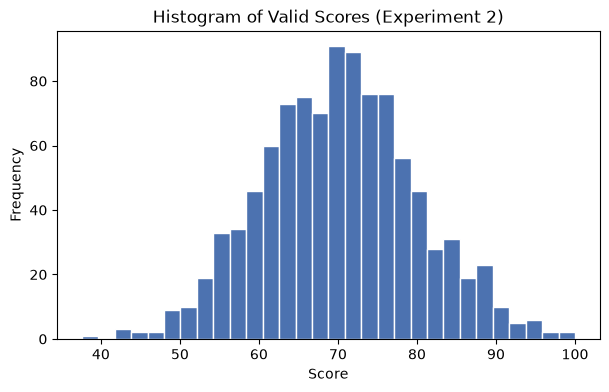

C:\Users\Administrator\AppData\Local\Temp\ipykernel_20664\3133361990.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax2.boxplot(valid, vert=True, patch_artist=True,


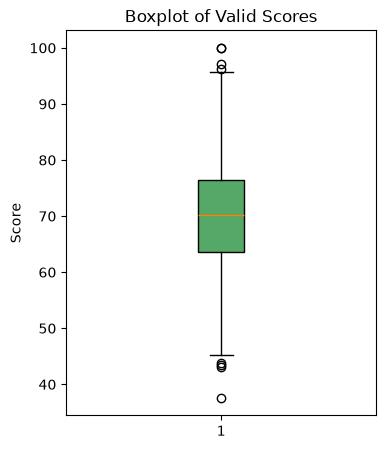

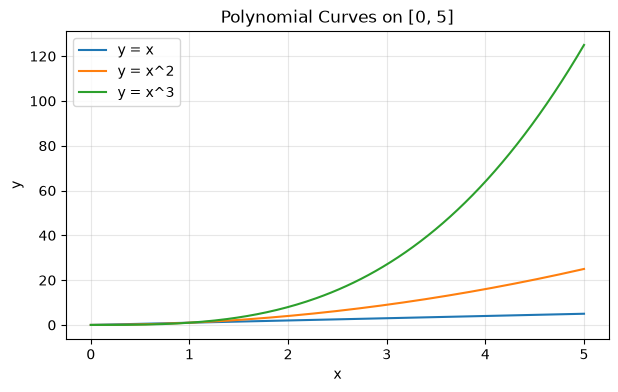

In [16]:
# 任务5：可视化（inline 显示）
# ---- 有效成绩直方图 ----
valid = scores[~np.isnan(scores)]
fig1, ax1 = plt.subplots(figsize=(7, 4))
ax1.hist(valid, bins=30, color="#4C72B0", edgecolor="white")
ax1.set_title("Histogram of Valid Scores (Experiment 2)")
ax1.set_xlabel("Score")
ax1.set_ylabel("Frequency")
plt.show()

# ---- 箱线图 ----
fig2, ax2 = plt.subplots(figsize=(4, 5))
ax2.boxplot(valid, vert=True, patch_artist=True,
            boxprops=dict(facecolor="#55A868"))
ax2.set_title("Boxplot of Valid Scores")
ax2.set_ylabel("Score")
plt.show()

# ---- 多函数折线图 ----
xs = np.linspace(0, 5, 200)
fig3, ax3 = plt.subplots(figsize=(7, 4))
ax3.plot(xs, xs,        label="y = x")
ax3.plot(xs, xs**2,     label="y = x^2")
ax3.plot(xs, xs**3,     label="y = x^3")
ax3.set_title("Polynomial Curves on [0, 5]")
ax3.set_xlabel("x")
ax3.set_ylabel("y")
ax3.legend()
ax3.grid(alpha=0.3)
plt.show()

# 实验 4：pandas Series、DataFrame 与内存中的 CSV 读写


### 任务 1：创建 DataFrame 并计算总分 / 平均分

用给定模拟数据创建 DataFrame，行索引设为姓名；计算 `Total`（三科总分）与 `Average`（三科平均分）；输出行索引、列名、前 3 行与基本统计信息。


In [17]:
# 任务1：创建 DataFrame
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")

df["Total"] = df[["Math", "English", "Python"]].sum(axis=1)
df["Average"] = df[["Math", "English", "Python"]].mean(axis=1).round(2)

print("行索引:", list(df.index))
print("列名  :", list(df.columns))
print("\n前 3 行:")
print(df.head(3))
print("\n基本统计信息:")
print(df[["Math", "English", "Python", "Total", "Average"]].describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名  : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total  Average
Name                                              
Alice     A    88       90      95    273    91.00
Bob       A    72       68      80    220    73.33
Carol     B    91       85      89    265    88.33

基本统计信息:
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.443333
std     9.907909   9.662643   8.547904   25.781130   8.595072
min    65.000000  68.000000  70.000000  208.000000  69.330000
25%    73.750000  74.000000  80.500000  225.750000  75.247500
50%    81.500000  81.000000  84.000000  250.000000  83.335000
75%    87.000000  88.750000  88.250000  263.000000  87.665000
max    91.000000  92.000000  95.000000  273.000000  91.000000


### 任务 2：loc / iloc 读取与筛选

用 `loc`（按标签）和 `iloc`（按位置）读取 Carol 的记录；筛选平均分不低于 80 的学生。


In [18]:
# 任务2：loc / iloc
print("loc 按标签读取 Carol:")
print(df.loc["Carol"])

print("\niloc 按位置读取 Carol (第3行, 位置索引2):")
print(df.iloc[2])

high = df[df["Average"] >= 80]
print("\n平均分不低于80的学生:")
print(high[["Math", "English", "Python", "Average"]])

loc 按标签读取 Carol:
Group          B
Math          91
English       85
Python        89
Total        265
Average    88.33
Name: Carol, dtype: object

iloc 按位置读取 Carol (第3行, 位置索引2):
Group          B
Math          91
English       85
Python        89
Total        265
Average    88.33
Name: Carol, dtype: object

平均分不低于80的学生:
       Math  English  Python  Average
Name                                 
Alice    88       90      95    91.00
Carol    91       85      89    88.33
Eva      79       92      86    85.67
Frank    84       77      82    81.00


### 任务 3：axis=0 与 axis=1 的均值

`mean(axis=0)` 沿行方向压缩，得到**每科**的均值；`mean(axis=1)` 沿列方向压缩，得到**每个学生**的均值。


In [19]:
# 任务3：axis 含义
col_mean = df[["Math", "English", "Python"]].mean(axis=0)
row_mean = df[["Math", "English", "Python"]].mean(axis=1)

print("axis=0 列均值（每科）:")
print(col_mean)
print("\naxis=1 行均值（每人）:")
print(row_mean.round(2))

axis=0 列均值（每科）:
Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

axis=1 行均值（每人）:
Name
Alice    91.00
Bob      73.33
Carol    88.33
David    69.33
Eva      85.67
Frank    81.00
dtype: float64


### 任务 4：apply / agg / rank

用 `apply` 计算每人三科最高分；用 `agg` 一次性得到每科的最小值、均值、最大值；对 `Python` 列用 `rank` 排名。


In [20]:
# 任务4：apply / agg / rank
df["MaxScore"] = df[["Math", "English", "Python"]].apply(max, axis=1)

agg_tbl = df[["Math", "English", "Python"]].agg(["min", "mean", "max"])
print("每科 min / mean / max:")
print(agg_tbl.round(2))

df["Python_Rank"] = df["Python"].rank(ascending=False).astype(int)
print("\nPython 列排名（1=最高）:")
print(df["Python_Rank"])

每科 min / mean / max:
       Math  English  Python
min   65.00    68.00   70.00
mean  79.83    80.83   83.67
max   91.00    92.00   95.00

Python 列排名（1=最高）:
Name
Alice    1
Bob      5
Carol    2
David    6
Eva      3
Frank    4
Name: Python_Rank, dtype: int64


### 任务 5：分组统计与 transform

按 `Group` 分组，统计每组人数与三科平均分；再用 `transform("mean")` 为每行增加其所在组的 Python 平均分。


In [21]:
# 任务5：groupby + transform
grp = df.groupby("Group")
print("每组人数与三科平均分:")
print(grp.size().rename("人数"))
print(grp[["Math", "English", "Python"]].mean().round(2))

df["Group_Python_Mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n为每行增加所在组的 Python 平均分:")
print(df[["Group", "Python", "Group_Python_Mean"]])

每组人数与三科平均分:
Group
A    3
B    3
Name: 人数, dtype: int64
        Math  English  Python
Group                        
A      79.67    83.33   87.00
B      80.00    78.33   80.33

为每行增加所在组的 Python 平均分:
      Group  Python  Group_Python_Mean
Name                                  
Alice     A      95          87.000000
Bob       A      80          87.000000
Carol     B      89          80.333333
David     B      70          80.333333
Eva       A      86          87.000000
Frank     B      82          80.333333


### 任务 6：filter 保留满足条件的组

用 `filter` 保留「Python 平均分不低于 80」的组，并输出保留的组与学生。


In [22]:
# 任务6：groupby.filter
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("Python 平均分 >= 80 的组所包含的学生:")
print(kept[["Group", "Python", "Average"]])
print("\n保留的组:", sorted(kept["Group"].unique()))

Python 平均分 >= 80 的组所包含的学生:
      Group  Python  Average
Name                        
Alice     A      95    91.00
Bob       A      80    73.33
Carol     B      89    88.33
David     B      70    69.33
Eva       A      86    85.67
Frank     B      82    81.00

保留的组: ['A', 'B']


### 任务 7：协方差与皮尔森相关系数

计算三科成绩之间的协方差矩阵与皮尔森相关系数矩阵；以「Math vs English」为例：协方差符号为正表示两科成绩同向变动，相关系数接近 1 表示强正相关。


In [23]:
# 任务7：协方差与相关系数
cov = df[["Math", "English", "Python"]].cov()
corr = df[["Math", "English", "Python"]].corr()

print("协方差矩阵:")
print(cov.round(2))
print("\n皮尔森相关系数矩阵:")
print(corr.round(3))

r_me = corr.loc["Math", "English"]
cov_me = cov.loc["Math", "English"]
print(f"\nMath vs English: 协方差={cov_me:.2f}(正号->同向变动), 相关系数={r_me:.3f}(接近1->强正相关)")

协方差矩阵:
          Math  English  Python
Math     98.17    62.57   74.93
English  62.57    93.37   62.53
Python   74.93    62.53   73.07

皮尔森相关系数矩阵:
          Math  English  Python
Math     1.000    0.654   0.885
English  0.654    1.000   0.757
Python   0.885    0.757   1.000

Math vs English: 协方差=62.57(正号->同向变动), 相关系数=0.654(接近1->强正相关)


# 实验总结

- **NumPy**：同构数组 + 向量化运算远胜 Python 列表；`reshape` 要求元素总数不变；逻辑索引需用 `|`/`&` 并按元素加括号；`*` 为逐元素乘、`@` 为矩阵乘。
- **随机抽样 / 缺失值**：固定种子保证可复现；`np.random.permutation` 返回副本而 `np.random.shuffle` 原地修改；`np.nan` 会污染普通统计，须用 `np.nan*` 系列函数。
- **SciPy / Matplotlib**：`linalg.solve` 解线性方程组、`optimize.root/minimize` 求根与极值、`stats.ttest_ind` 做假设检验；Matplotlib 通过 `inline` 后端在 Notebook 内直接出图，并补充标题、坐标轴标签与图例。
- **pandas**：DataFrame 以行索引承载姓名；`loc` 按标签、`iloc` 按位置；`axis` 决定聚合方向；`apply/agg/rank` 灵活变换；`groupby` + `transform/filter` 完成分组统计与筛选；`cov/corr` 刻画变量间关系。

> 本 Notebook 已在独立 conda 环境（非 base）中**重启内核并运行全部代码**，所有输出均已嵌入。
